In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Load Fitbit historical sales data
df = pd.read_csv("data/fitbit_sales_businessofapps_2014_2025.csv")

# Display the dataset
display(df)

,year,device_sales_millions
0,2014,10.9
1,2015,21.4
2,2016,23.2
3,2017,25.4
4,2018,13.9
5,2019,16.0
6,2020,10.8
7,2021,10.6
8,2022,9.2
9,2023,6.6


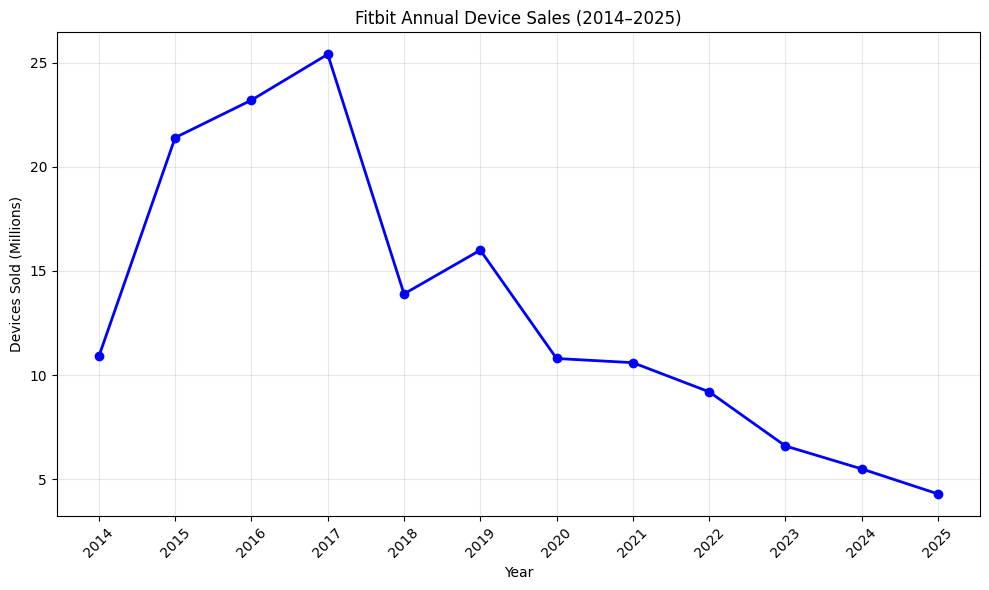

In [4]:
# Plot Fitbit annual device sales (2014–2025)

plt.figure(figsize=(10, 6))

plt.plot(
    df["year"],
    df["device_sales_millions"],
    marker="o",
    color="blue",
    linewidth=2
)

plt.title("Fitbit Annual Device Sales (2014–2025)")
plt.xlabel("Year")
plt.ylabel("Devices Sold (Millions)")

plt.xticks(df["year"], rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save graph to HW1/img folder
plt.savefig("img/fitbit_annual_sales.png", dpi=300)

plt.show()

In [5]:
from scipy.optimize import least_squares

# Historical Fitbit sales (millions)
years = df["year"].to_numpy()
actual_sales = df["device_sales_millions"].to_numpy()

# Bass Diffusion Model
def bass_model(p, q, M, periods):
    cumulative = 0
    predictions = []

    for t in range(periods):
        new_adopters = (p + q * cumulative / M) * (M - cumulative)
        predictions.append(new_adopters)
        cumulative += new_adopters

    return np.array(predictions)

# Function to calculate prediction errors
def residuals(params):
    p, q, M = params
    predicted = bass_model(p, q, M, len(actual_sales))
    return predicted - actual_sales

# Estimate parameters
result = least_squares(
    residuals,
    x0=[0.05, 0.3, 200],
    bounds=(
        [0.000001, 0.000001, actual_sales.sum() + 0.01],
        [0.5, 2.0, 1000]
    )
)

p, q, M = result.x

print(f"Coefficient of innovation (p): {p:.4f}")
print(f"Coefficient of imitation (q): {q:.4f}")
print(f"Market potential (M): {M:.2f} million")

Coefficient of innovation (p): 0.1047
Coefficient of imitation (q): 0.2534
Market potential (M): 160.19 million


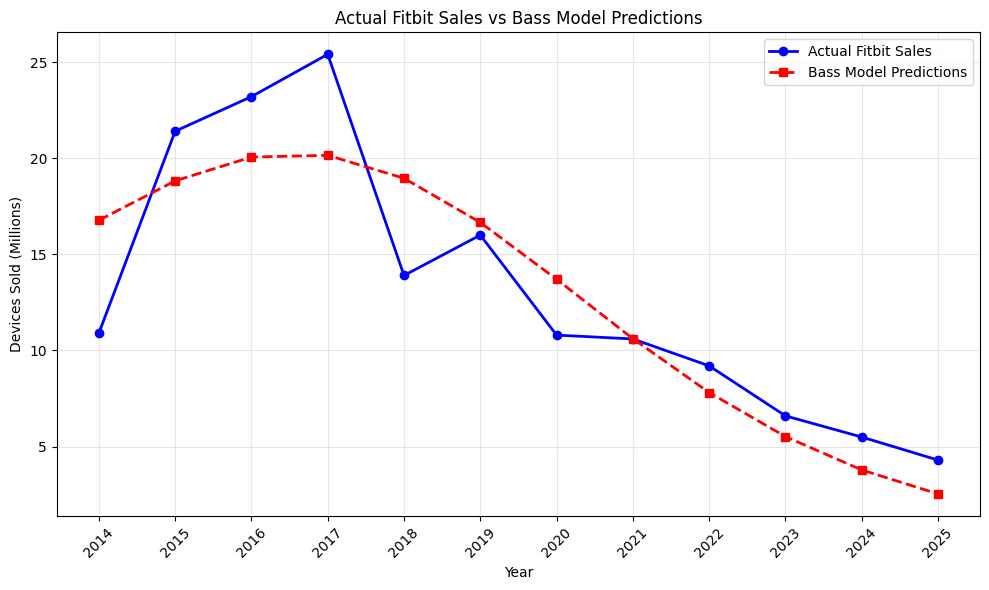

In [7]:
# Calculate Bass Model predictions
predicted_sales = bass_model(p, q, M, len(years))

# comparison graph
plt.figure(figsize=(10, 6))

plt.plot(
    years,
    actual_sales,
    marker="o",
    color="blue",
    linewidth=2,
    label="Actual Fitbit Sales"
)

plt.plot(
    years,
    predicted_sales,
    marker="s",
    linestyle="--",
    color="red",
    linewidth=2,
    label="Bass Model Predictions"
)

plt.title("Actual Fitbit Sales vs Bass Model Predictions")
plt.xlabel("Year")
plt.ylabel("Devices Sold (Millions)")

plt.xticks(years, rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save graph
plt.savefig("img/fitbit_bass_model_comparison.png", dpi=300)

plt.show()

In [8]:
# Model accuracy

# Root Mean Squared Error (RMSE)
rmse = np.sqrt(np.mean((actual_sales - predicted_sales) ** 2))

# R-squared (R²)
ss_res = np.sum((actual_sales - predicted_sales) ** 2)
ss_tot = np.sum((actual_sales - np.mean(actual_sales)) ** 2)

r_squared = 1 - (ss_res / ss_tot)

# Display results
print(f"RMSE: {rmse:.4f} million devices")
print(f"R-squared (R²): {r_squared:.4f}")

# Create comparison table
comparison_df = pd.DataFrame({
    "Year": years,
    "Actual_Sales_Millions": actual_sales,
    "Bass_Predictions_Millions": predicted_sales
})

display(comparison_df)

# Save results
comparison_df.to_csv(
    "data/fitbit_bass_fit_results.csv",
    index=False
)

RMSE: 3.1897 million devices
R-squared (R²): 0.7740


,Year,Actual_Sales_Millions,Bass_Predictions_Millions
0,2014,10.9,16.770411
1,2015,21.4,18.819433
2,2016,23.2,20.059251
3,2017,25.4,20.147027
4,2018,13.9,18.953753
5,2019,16.0,16.658767
6,2020,10.8,13.703160
7,2021,10.6,10.613764
8,2022,9.2,7.812586
9,2023,6.6,5.522961


In [10]:

# Estimate Oura Ring 4 global market potential

global_smart_ring_shipments = 4.0  # millions, 2025 forecast
oura_market_share = 0.74           # Oura H1 2025 share

# Peak annual Fitbit sales from our dataset
fitbit_peak_sales = actual_sales.max()

# Fermi-style scaling of Fitbit's estimated market potential
M_oura = M * (
    global_smart_ring_shipments * oura_market_share
    / fitbit_peak_sales
)

print(f"Estimated Oura market potential: {M_oura:.2f} million")

# Forecast 2025–2034 
forecast_years = np.arange(2025, 2035)

oura_new_adopters = bass_model(
    p, q, M_oura, len(forecast_years)
)

oura_cumulative_adopters = np.cumsum(oura_new_adopters)

# Create forecast table
oura_forecast = pd.DataFrame({
    "Year": forecast_years,
    "New_Adopters_Millions": oura_new_adopters,
    "Cumulative_Adopters_Millions": oura_cumulative_adopters
})

display(oura_forecast.round(3))

# Save results
oura_forecast.to_csv(
    "data/oura_ring_4_forecast.csv",
    index=False
)


Estimated Oura market potential: 18.67 million


,Year,New_Adopters_Millions,Cumulative_Adopters_Millions
0,2025,1.954,1.954
1,2026,2.193,4.147
2,2027,2.338,6.485
3,2028,2.348,8.833
4,2029,2.209,11.042
5,2030,1.941,12.983
6,2031,1.597,14.580
7,2032,1.237,15.817
8,2033,0.910,16.727
9,2034,0.644,17.371


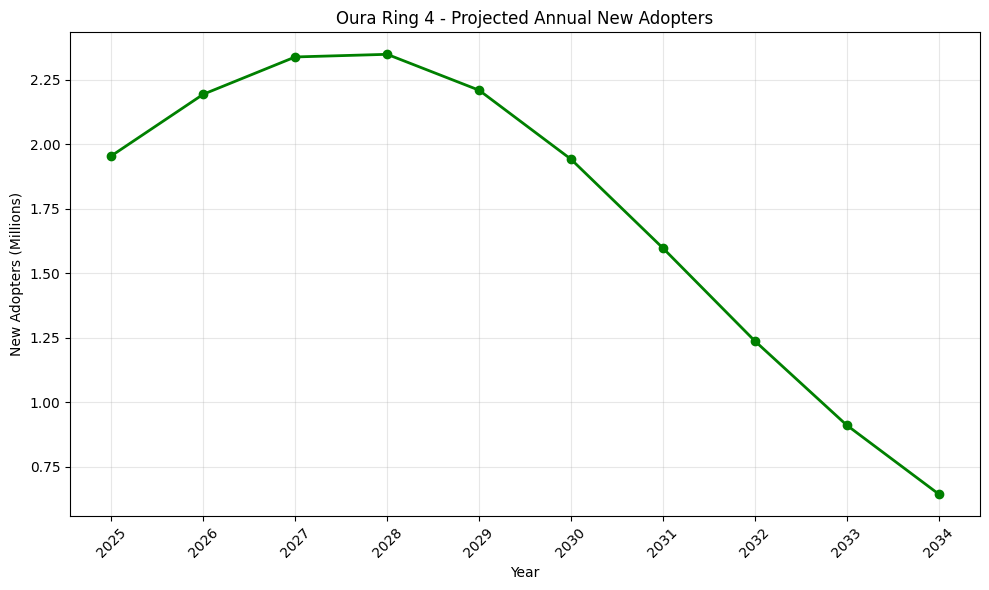

In [11]:

# Graph 1: Annual new adopters

plt.figure(figsize=(10, 6))

plt.plot(
    forecast_years,
    oura_new_adopters,
    marker="o",
    color="green",
    linewidth=2
)

plt.title("Oura Ring 4 - Projected Annual New Adopters")
plt.xlabel("Year")
plt.ylabel("New Adopters (Millions)")
plt.xticks(forecast_years, rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("img/oura_annual_adopters.png", dpi=300)
plt.show()


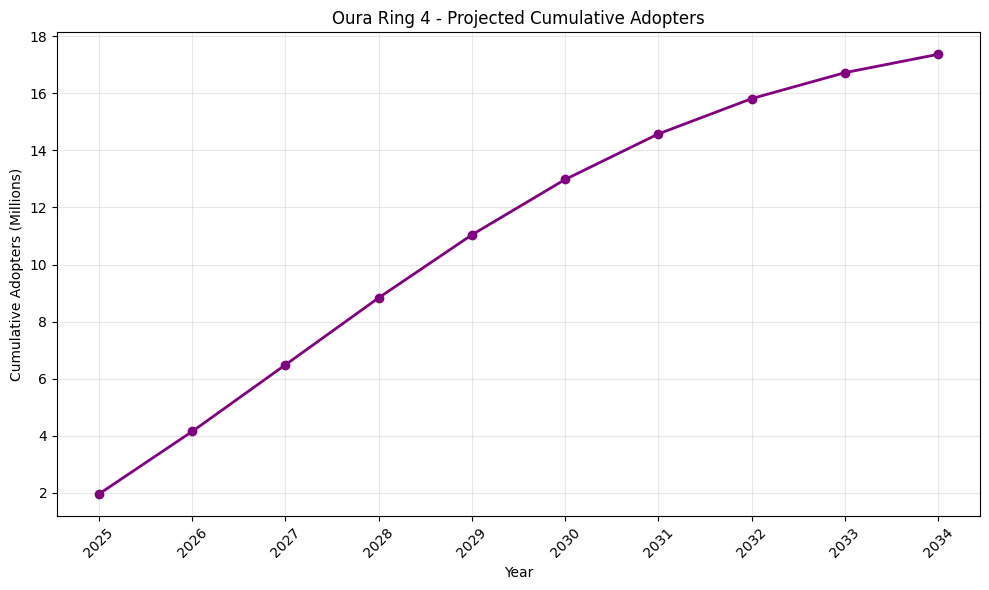

In [12]:
# Graph 2: Cumulative adopters

plt.figure(figsize=(10, 6))

plt.plot(
    forecast_years,
    oura_cumulative_adopters,
    marker="o",
    color="purple",
    linewidth=2
)

plt.title("Oura Ring 4 - Projected Cumulative Adopters")
plt.xlabel("Year")
plt.ylabel("Cumulative Adopters (Millions)")
plt.xticks(forecast_years, rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("img/oura_cumulative_adopters.png", dpi=300)
plt.show()


In [15]:
 from pathlib import Path
import nbformat

# Read our Markdown report
report_text = Path("report/report_source.md").read_text(
    encoding="utf-8"
)

# Create a notebook containing the report
report_notebook = nbformat.v4.new_notebook(
    cells=[nbformat.v4.new_markdown_cell(report_text)]
)

# Save the report preview
nbformat.write(
    report_notebook,
    "report/report_preview.ipynb"
)

In [16]:
!jupyter nbconvert --to html --output report_preview.html --output-dir report report/report_preview.ipynb

[NbConvertApp] Converting notebook report/report_preview.ipynb to html
[NbConvertApp] Writing 286254 bytes to report/report_preview.html
